In [1]:
# Books Market Analysis – End-to-End Data Analytics Project

**Website:** http://books.toscrape.com/  
**Libraries:** Requests, BeautifulSoup, Pandas, Regular Expressions, Matplotlib, Seaborn

This notebook is designed to complete the assignment workflow:
1. Collect book data from all catalogue pages using Requests + BeautifulSoup.
2. Clean the data with Pandas and regular expressions.
3. Create at least three engineered features.
4. Perform univariate, bivariate and multivariate EDA.
5. Answer 10 business questions.
6. Generate business insights and recommendations.
7. Export scraped data, cleaned data, charts and a text report.

> Run the notebook from top to bottom with an internet connection. The website is a practice scraping site. The CSV files and charts are generated by the notebook when it runs successfully.

## 1. Import libraries and configure scraping
import re
import time
from pathlib import Path
from urllib.parse import urljoin

import requests
import pandas as pd
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns

BASE_URL = "http://books.toscrape.com/"
OUTPUT_DIR = Path("books_market_analysis_output")
CHART_DIR = OUTPUT_DIR / "visualizations"
OUTPUT_DIR.mkdir(exist_ok=True)
CHART_DIR.mkdir(exist_ok=True)

HEADERS = {
    "User-Agent": "Mozilla/5.0 (compatible; BooksMarketAnalysisStudentProject/1.0)",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8",
    "Accept-Language": "en-US,en;q=0.9"
}

session = requests.Session()
session.headers.update(HEADERS)

response = session.get(BASE_URL, timeout=30)
response.raise_for_status()
print("Website status:", response.status_code)

## 2. Scrape all catalogue pages dynamically
def get_soup(url):
    response = session.get(url, timeout=30)
    response.raise_for_status()
    return BeautifulSoup(response.text, "html.parser")

def scrape_book_page(page_url):
    soup = get_soup(page_url)
    records = []

    for book in soup.select("article.product_pod"):
        title_tag = book.select_one("h3 a")
        price_tag = book.select_one(".price_color")
        availability_tag = book.select_one(".availability")
        rating_tag = book.select_one("p.star-rating")

        title = title_tag.get("title", "").strip() if title_tag else None
        relative_url = title_tag.get("href", "") if title_tag else ""
        product_url = urljoin(page_url, relative_url)

        # The listing page contains price, availability and rating.
        records.append({
            "Book_Name": title,
            "Price_Raw": price_tag.get_text(strip=True) if price_tag else None,
            "Availability_Raw": availability_tag.get_text(" ", strip=True) if availability_tag else None,
            "Rating_Raw": " ".join(rating_tag.get("class", [])[1:]) if rating_tag else None,
            "Product_URL": product_url,
            "Catalogue_Page_URL": page_url
        })

    next_tag = soup.select_one("li.next a")
    next_url = urljoin(page_url, next_tag.get("href")) if next_tag else None
    return records, next_url

all_records = []
page_url = BASE_URL + "catalogue/page-1.html"
page_count = 0

while page_url:
    page_records, next_page_url = scrape_book_page(page_url)
    all_records.extend(page_records)
    page_count += 1
    print(f"Scraped page {page_count}: {len(page_records)} books")
    page_url = next_page_url
    time.sleep(0.2)  # polite pause between requests

scraped_df = pd.DataFrame(all_records)
scraped_path = OUTPUT_DIR / "scraped_books.csv"
scraped_df.to_csv(scraped_path, index=False)
print("Pages scraped:", page_count)
print("Books scraped:", len(scraped_df))
display(scraped_df.head())

## 3. Data cleaning using Pandas and Regular Expressions

Regex is used for:
1. Removing the currency symbol and extracting the numeric price.
2. Extracting the availability count.
3. Normalizing rating text.
4. Extracting the book title text safely.
5. Standardizing whitespace and non-numeric characters in numeric fields.

The website's catalogue listing does not expose category, ISBN, or detailed product specifications in the listing card. This project therefore analyzes the fields genuinely available on the catalogue pages rather than inventing unavailable fields.

clean_df = scraped_df.copy()

# Regex task 1: keep only digits and decimal point from price.
clean_df["Price"] = clean_df["Price_Raw"].astype("string").str.replace(
    r"[^0-9.]", "", regex=True
)
clean_df["Price"] = pd.to_numeric(clean_df["Price"], errors="coerce")

# Regex task 2: extract the stock quantity from strings such as "In stock (22 available)".
clean_df["Stock_Count"] = clean_df["Availability_Raw"].astype("string").str.extract(
    r"\((\d+)\s+available\)", expand=False
)
clean_df["Stock_Count"] = pd.to_numeric(clean_df["Stock_Count"], errors="coerce")

# Regex task 3: normalize rating values to title case words.
clean_df["Rating"] = clean_df["Rating_Raw"].astype("string").str.extract(
    r"(One|Two|Three|Four|Five)", flags=re.IGNORECASE, expand=False
).str.title()

rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
clean_df["Rating_Score"] = clean_df["Rating"].map(rating_map).astype("Float64")

# Regex task 4: normalize book titles by collapsing repeated whitespace.
clean_df["Book_Name"] = clean_df["Book_Name"].astype("string").str.replace(
    r"\s+", " ", regex=True
).str.strip()

# Regex task 5: standardize availability text and extract its status.
clean_df["Availability_Status"] = clean_df["Availability_Raw"].astype("string").str.extract(
    r"(In stock|Out of stock)", flags=re.IGNORECASE, expand=False
).str.title()

# Remove exact duplicate rows and rows without essential title/price.
clean_df = clean_df.drop_duplicates()
clean_df = clean_df.dropna(subset=["Book_Name", "Price"]).copy()

# Appropriate data types.
clean_df["Price"] = clean_df["Price"].astype(float)
clean_df["Stock_Count"] = clean_df["Stock_Count"].astype("Int64")
clean_df["Rating_Score"] = clean_df["Rating_Score"].astype("Float64")

# Regex task 6: final sanitation of any unexpected currency/text residue.
clean_df["Price_Text_Clean"] = clean_df["Price_Raw"].astype("string").str.replace(
    r"[^0-9.]", "", regex=True
)

cleaned_path = OUTPUT_DIR / "cleaned_books.csv"
clean_df.to_csv(cleaned_path, index=False)
print("Rows after cleaning:", len(clean_df))
display(clean_df.head())
print(clean_df.dtypes)

## 4. Feature engineering – create at least 3 new columns
# Price bands are based on the distribution of this collected dataset.
q1 = clean_df["Price"].quantile(0.33)
q2 = clean_df["Price"].quantile(0.66)

clean_df["Price_Category"] = pd.cut(
    clean_df["Price"],
    bins=[-float("inf"), q1, q2, float("inf")],
    labels=["Budget", "Mid-Range", "Expensive"],
    include_lowest=True
)

clean_df["Rating_Category"] = pd.cut(
    clean_df["Rating_Score"].astype(float),
    bins=[0, 2, 3, 5],
    labels=["Low", "Average", "High"],
    include_lowest=True
)

clean_df["Availability_Flag"] = clean_df["Availability_Status"].map(
    {"In stock": "Available", "Out Of Stock": "Unavailable", "Out of stock": "Unavailable"}
).fillna("Unknown")

clean_df.to_csv(cleaned_path, index=False)
display(clean_df[["Book_Name", "Price", "Rating_Score", "Price_Category",
                  "Rating_Category", "Availability_Flag"]].head())

## 5. Exploratory Data Analysis (EDA)
### Univariate analysis
print("Dataset shape:", clean_df.shape)
display(clean_df[["Price", "Rating_Score", "Stock_Count"]].describe())
display(clean_df["Rating"].value_counts(dropna=False))
display(clean_df["Availability_Status"].value_counts(dropna=False))

### Create at least 8 visualizations
sns.set_theme()

def save_chart(filename):
    plt.tight_layout()
    plt.savefig(CHART_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

# 1. Price distribution – univariate
plt.figure(figsize=(8, 5))
sns.histplot(clean_df["Price"], bins=20, kde=True)
plt.title("Book Price Distribution")
plt.xlabel("Price (£)")
save_chart("01_price_distribution.png")

# 2. Rating count – univariate
plt.figure(figsize=(8, 5))
order = ["One", "Two", "Three", "Four", "Five"]
sns.countplot(data=clean_df, x="Rating", order=order)
plt.title("Book Rating Distribution")
plt.xlabel("Rating")
save_chart("02_rating_distribution.png")

# 3. Availability – univariate
plt.figure(figsize=(7, 5))
clean_df["Availability_Status"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Book Availability Status")
plt.ylabel("")
save_chart("03_availability_distribution.png")

# 4. Price by rating – bivariate
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_df, x="Rating", y="Price", order=order)
plt.title("Price Distribution by Rating")
plt.xlabel("Rating")
plt.ylabel("Price (£)")
save_chart("04_price_by_rating_boxplot.png")

# 5. Average price by rating – bivariate
plt.figure(figsize=(8, 5))
avg_price_rating = clean_df.groupby("Rating", observed=False)["Price"].mean().reindex(order)
sns.barplot(x=avg_price_rating.index, y=avg_price_rating.values)
plt.title("Average Book Price by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Price (£)")
save_chart("05_average_price_by_rating.png")

# 6. Price category distribution – univariate
plt.figure(figsize=(8, 5))
sns.countplot(data=clean_df, x="Price_Category",
              order=["Budget", "Mid-Range", "Expensive"])
plt.title("Books by Price Category")
plt.xlabel("Price Category")
save_chart("06_price_category_distribution.png")

# 7. Price vs rating – bivariate
plt.figure(figsize=(8, 5))
sns.scatterplot(data=clean_df, x="Rating_Score", y="Price", alpha=0.7)
plt.title("Book Price vs Rating")
plt.xlabel("Rating (1–5)")
plt.ylabel("Price (£)")
save_chart("07_price_vs_rating_scatter.png")

# 8. Price category and rating category – multivariate
plt.figure(figsize=(8, 5))
cross_tab = pd.crosstab(clean_df["Price_Category"], clean_df["Rating_Category"])
sns.heatmap(cross_tab, annot=True, fmt="d", cmap="Blues")
plt.title("Price Category vs Rating Category")
plt.xlabel("Rating Category")
plt.ylabel("Price Category")
save_chart("08_price_rating_heatmap.png")

# 9. Top 10 expensive books – bivariate
plt.figure(figsize=(10, 6))
top10 = clean_df.nlargest(10, "Price").sort_values("Price")
sns.barplot(data=top10, x="Price", y="Book_Name")
plt.title("Top 10 Most Expensive Books")
plt.xlabel("Price (£)")
plt.ylabel("Book")
save_chart("09_top_10_expensive_books.png")

# 10. Stock quantity distribution – univariate
plt.figure(figsize=(8, 5))
sns.histplot(clean_df["Stock_Count"].dropna(), bins=15)
plt.title("Stock Quantity Distribution")
plt.xlabel("Number of copies available")
save_chart("10_stock_quantity_distribution.png")

## 6. Business questions with answers
answers = {
    "Q1. How many books were collected?": f"{len(clean_df)} books.",
    "Q2. What is the average book price?": f"£{clean_df['Price'].mean():.2f}.",
    "Q3. What is the minimum book price?": f"£{clean_df['Price'].min():.2f}.",
    "Q4. What is the maximum book price?": f"£{clean_df['Price'].max():.2f}.",
    "Q5. What is the median book price?": f"£{clean_df['Price'].median():.2f}.",
    "Q6. What is the average book rating?": f"{clean_df['Rating_Score'].mean():.2f} out of 5.",
    "Q7. Which rating has the highest number of books?": (
        f"{clean_df['Rating'].value_counts().idxmax()} stars "
        f"({clean_df['Rating'].value_counts().max()} books)."
    ),
    "Q8. How many books received a 5-star rating?": (
        f"{int((clean_df['Rating_Score'] == 5).sum())} books."
    ),
    "Q9. What is the availability status of the collected books?": (
        clean_df["Availability_Status"].value_counts(dropna=False).to_dict()
    ),
    "Q10. How many books were collected per catalogue page on average?": (
        f"{len(clean_df) / max(clean_df['Catalogue_Page_URL'].nunique(), 1):.1f} books."
    )
}
for question, answer in answers.items():
    print(question)
    print("Answer:", answer, "\\n")

## 7. Business insights – generated from the collected data
rating_counts = clean_df["Rating"].value_counts()
price_by_rating = clean_df.groupby("Rating", observed=False)["Price"].mean().dropna()
price_category_counts = clean_df["Price_Category"].value_counts()
availability_counts = clean_df["Availability_Status"].value_counts()

insights = [
    f"The dataset contains {len(clean_df)} unique book records after cleaning.",
    f"The average listed book price is £{clean_df['Price'].mean():.2f}, while the median is £{clean_df['Price'].median():.2f}.",
    f"The most common rating is {rating_counts.idxmax()} stars, representing {rating_counts.max()} books.",
    f"There are {int((clean_df['Rating_Score'] == 5).sum())} five-star books in the collected catalogue.",
    f"The highest-priced book is '{clean_df.loc[clean_df['Price'].idxmax(), 'Book_Name']}' at £{clean_df['Price'].max():.2f}.",
    f"The lowest-priced book is '{clean_df.loc[clean_df['Price'].idxmin(), 'Book_Name']}' at £{clean_df['Price'].min():.2f}.",
    f"The largest price segment is {price_category_counts.idxmax()} with {price_category_counts.max()} books.",
    f"Availability counts in the scrape are {availability_counts.to_dict()}."
]
for i, item in enumerate(insights, 1):
    print(f"{i}. {item}")

## 8. Business recommendations
recommendations = [
    "Use the observed price distribution to create clear budget, mid-range and premium book collections.",
    "Highlight highly rated books in recommendation sections, while retaining enough variety across price points.",
    "Monitor books with low stock counts and prioritize replenishment where demand indicators are strong.",
    "Use rating and price together when planning promotions; avoid assuming that higher price automatically means higher rating.",
    "Repeat the scrape periodically and compare price, rating and availability changes over time before making inventory decisions."
]
for i, item in enumerate(recommendations, 1):
    print(f"{i}. {item}")

## 9. Export project deliverables
# Save business questions, insights and recommendations.
report_path = OUTPUT_DIR / "business_questions_insights_recommendations.txt"
with open(report_path, "w", encoding="utf-8") as f:
    f.write("BOOKS MARKET ANALYSIS – BUSINESS QUESTIONS AND ANSWERS\\n\\n")
    for q, a in answers.items():
        f.write(q + "\\n" + "Answer: " + str(a) + "\\n\\n")
    f.write("\\nBUSINESS INSIGHTS\\n")
    for i, item in enumerate(insights, 1):
        f.write(f"{i}. {item}\\n")
    f.write("\\nBUSINESS RECOMMENDATIONS\\n")
    for i, item in enumerate(recommendations, 1):
        f.write(f"{i}. {item}\\n")

# Save final CSVs in output folder.
scraped_df.to_csv(OUTPUT_DIR / "scraped_books.csv", index=False)
clean_df.to_csv(OUTPUT_DIR / "cleaned_books.csv", index=False)

print("Project outputs saved in:", OUTPUT_DIR.resolve())
print("Files:", [p.name for p in OUTPUT_DIR.iterdir()])

## 10. Conclusion

This project demonstrates an end-to-end analytics workflow using a public practice website. The scraped catalogue data is transformed into structured data, cleaned with Pandas and regular expressions, enriched with engineered features, and analyzed through visualizations and business questions.

**Important:** The figures in the notebook are calculated from the live scrape when the notebook is run. They may differ from figures in an earlier presentation if the website data changes or the earlier dataset was collected at a different time.


SyntaxError: unterminated string literal (detected at line 110) (3233517127.py, line 110)

# Books Market Analysis – End-to-End Data Analytics Project

**Website:** http://books.toscrape.com/  
**Libraries:** Requests, BeautifulSoup, Pandas, Regular Expressions, Matplotlib, Seaborn

This notebook is designed to complete the assignment workflow:
1. Collect book data from all catalogue pages using Requests + BeautifulSoup.
2. Clean the data with Pandas and regular expressions.
3. Create at least three engineered features.
4. Perform univariate, bivariate and multivariate EDA.
5. Answer 10 business questions.
6. Generate business insights and recommendations.
7. Export scraped data, cleaned data, charts and a text report.

> Run the notebook from top to bottom with an internet connection. The website is a practice scraping site. The CSV files and charts are generated by the notebook when it runs successfully.


# 1. Import libraries and configure scraping


In [2]:
import re
import time
from pathlib import Path
from urllib.parse import urljoin

import requests
import pandas as pd
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns

BASE_URL = "http://books.toscrape.com/"
OUTPUT_DIR = Path("books_market_analysis_output")
CHART_DIR = OUTPUT_DIR / "visualizations"
OUTPUT_DIR.mkdir(exist_ok=True)
CHART_DIR.mkdir(exist_ok=True)

HEADERS = {
    "User-Agent": "Mozilla/5.0 (compatible; BooksMarketAnalysisStudentProject/1.0)",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8",
    "Accept-Language": "en-US,en;q=0.9"
}

session = requests.Session()
session.headers.update(HEADERS)

response = session.get(BASE_URL, timeout=30)
response.raise_for_status()
print("Website status:", response.status_code)

Website status: 200


In [3]:
## 2. Scrape all catalogue pages dynamically
def get_soup(url):
    response = session.get(url, timeout=30)
    response.raise_for_status()
    return BeautifulSoup(response.text, "html.parser")

def scrape_book_page(page_url):
    soup = get_soup(page_url)
    records = []

    for book in soup.select("article.product_pod"):
        title_tag = book.select_one("h3 a")
        price_tag = book.select_one(".price_color")
        availability_tag = book.select_one(".availability")
        rating_tag = book.select_one("p.star-rating")

        title = title_tag.get("title", "").strip() if title_tag else None
        relative_url = title_tag.get("href", "") if title_tag else ""
        product_url = urljoin(page_url, relative_url)

        # The listing page contains price, availability and rating.
        records.append({
            "Book_Name": title,
            "Price_Raw": price_tag.get_text(strip=True) if price_tag else None,
            "Availability_Raw": availability_tag.get_text(" ", strip=True) if availability_tag else None,
            "Rating_Raw": " ".join(rating_tag.get("class", [])[1:]) if rating_tag else None,
            "Product_URL": product_url,
            "Catalogue_Page_URL": page_url
        })

    next_tag = soup.select_one("li.next a")
    next_url = urljoin(page_url, next_tag.get("href")) if next_tag else None
    return records, next_url

all_records = []
page_url = BASE_URL + "catalogue/page-1.html"
page_count = 0

while page_url:
    page_records, next_page_url = scrape_book_page(page_url)
    all_records.extend(page_records)
    page_count += 1
    print(f"Scraped page {page_count}: {len(page_records)} books")
    page_url = next_page_url
    time.sleep(0.2)  # polite pause between requests

scraped_df = pd.DataFrame(all_records)
scraped_path = OUTPUT_DIR / "scraped_books.csv"
scraped_df.to_csv(scraped_path, index=False)
print("Pages scraped:", page_count)
print("Books scraped:", len(scraped_df))
display(scraped_df.head())


Scraped page 1: 20 books
Scraped page 2: 20 books
Scraped page 3: 20 books
Scraped page 4: 20 books
Scraped page 5: 20 books
Scraped page 6: 20 books
Scraped page 7: 20 books
Scraped page 8: 20 books
Scraped page 9: 20 books
Scraped page 10: 20 books
Scraped page 11: 20 books
Scraped page 12: 20 books
Scraped page 13: 20 books
Scraped page 14: 20 books
Scraped page 15: 20 books
Scraped page 16: 20 books
Scraped page 17: 20 books
Scraped page 18: 20 books
Scraped page 19: 20 books
Scraped page 20: 20 books
Scraped page 21: 20 books
Scraped page 22: 20 books
Scraped page 23: 20 books
Scraped page 24: 20 books
Scraped page 25: 20 books
Scraped page 26: 20 books
Scraped page 27: 20 books
Scraped page 28: 20 books
Scraped page 29: 20 books
Scraped page 30: 20 books
Scraped page 31: 20 books
Scraped page 32: 20 books
Scraped page 33: 20 books
Scraped page 34: 20 books
Scraped page 35: 20 books
Scraped page 36: 20 books
Scraped page 37: 20 books
Scraped page 38: 20 books
Scraped page 39: 20 b

,Book_Name,Price_Raw,Availability_Raw,Rating_Raw,Product_URL,Catalogue_Page_URL
0,A Light in the Attic,Â£51.77,In stock,Three,http://books.toscrape.com/catalogue/a-light-in...,http://books.toscrape.com/catalogue/page-1.html
1,Tipping the Velvet,Â£53.74,In stock,One,http://books.toscrape.com/catalogue/tipping-th...,http://books.toscrape.com/catalogue/page-1.html
2,Soumission,Â£50.10,In stock,One,http://books.toscrape.com/catalogue/soumission...,http://books.toscrape.com/catalogue/page-1.html
3,Sharp Objects,Â£47.82,In stock,Four,http://books.toscrape.com/catalogue/sharp-obje...,http://books.toscrape.com/catalogue/page-1.html
4,Sapiens: A Brief History of Humankind,Â£54.23,In stock,Five,http://books.toscrape.com/catalogue/sapiens-a-...,http://books.toscrape.com/catalogue/page-1.html


In [7]:
## 3. Data cleaning using Pandas and Regular Expressions

'''Regex is used for:
1. Removing the currency symbol and extracting the numeric price.
2. Extracting the availability count.
3. Normalizing rating text.
4. Extracting the book title text safely.
5. Standardizing whitespace and non-numeric characters in numeric fields.

The website's catalogue listing does not expose category, ISBN, or detailed product specifications in the listing card. This project therefore analyzes the fields genuinely available on the catalogue pages rather than inventing unavailable fields.
'''
clean_df = scraped_df.copy()

# Regex task 1: keep only digits and decimal point from price.
clean_df["Price"] = clean_df["Price_Raw"].astype("string").str.replace(
    r"[^0-9.]", "", regex=True
)
clean_df["Price"] = pd.to_numeric(clean_df["Price"], errors="coerce")

# Regex task 2: extract the stock quantity from strings such as "In stock (22 available)".
clean_df["Stock_Count"] = clean_df["Availability_Raw"].astype("string").str.extract(
    r"\((\d+)\s+available\)", expand=False
)
clean_df["Stock_Count"] = pd.to_numeric(clean_df["Stock_Count"], errors="coerce")

# Regex task 3: normalize rating values to title case words.
clean_df["Rating"] = clean_df["Rating_Raw"].astype("string").str.extract(
    r"(One|Two|Three|Four|Five)", flags=re.IGNORECASE, expand=False
).str.title()

rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
clean_df["Rating_Score"] = clean_df["Rating"].map(rating_map).astype("Float64")

# Regex task 4: normalize book titles by collapsing repeated whitespace.
clean_df["Book_Name"] = clean_df["Book_Name"].astype("string").str.replace(
    r"\s+", " ", regex=True
).str.strip()

# Regex task 5: standardize availability text and extract its status.
clean_df["Availability_Status"] = clean_df["Availability_Raw"].astype("string").str.extract(
    r"(In stock|Out of stock)", flags=re.IGNORECASE, expand=False
).str.title()

# Remove exact duplicate rows and rows without essential title/price.
clean_df = clean_df.drop_duplicates()
clean_df = clean_df.dropna(subset=["Book_Name", "Price"]).copy()

# Appropriate data types.
clean_df["Price"] = clean_df["Price"].astype(float)
clean_df["Stock_Count"] = clean_df["Stock_Count"].astype("Int64")
clean_df["Rating_Score"] = clean_df["Rating_Score"].astype("Float64")

# Regex task 6: final sanitation of any unexpected currency/text residue.
clean_df["Price_Text_Clean"] = clean_df["Price_Raw"].astype("string").str.replace(
    r"[^0-9.]", "", regex=True
)

cleaned_path = OUTPUT_DIR / "cleaned_books.csv"
clean_df.to_csv(cleaned_path, index=False)
print("Rows after cleaning:", len(clean_df))
display(clean_df.head())
print(clean_df.dtypes)


Rows after cleaning: 1000


,Book_Name,Price_Raw,Availability_Raw,Rating_Raw,Product_URL,Catalogue_Page_URL,Price,Stock_Count,Rating,Rating_Score,Availability_Status,Price_Text_Clean
0,A Light in the Attic,Â£51.77,In stock,Three,http://books.toscrape.com/catalogue/a-light-in...,http://books.toscrape.com/catalogue/page-1.html,51.77,<NA>,Three,3.0,In Stock,51.77
1,Tipping the Velvet,Â£53.74,In stock,One,http://books.toscrape.com/catalogue/tipping-th...,http://books.toscrape.com/catalogue/page-1.html,53.74,<NA>,One,1.0,In Stock,53.74
2,Soumission,Â£50.10,In stock,One,http://books.toscrape.com/catalogue/soumission...,http://books.toscrape.com/catalogue/page-1.html,50.10,<NA>,One,1.0,In Stock,50.10
3,Sharp Objects,Â£47.82,In stock,Four,http://books.toscrape.com/catalogue/sharp-obje...,http://books.toscrape.com/catalogue/page-1.html,47.82,<NA>,Four,4.0,In Stock,47.82
4,Sapiens: A Brief History of Humankind,Â£54.23,In stock,Five,http://books.toscrape.com/catalogue/sapiens-a-...,http://books.toscrape.com/catalogue/page-1.html,54.23,<NA>,Five,5.0,In Stock,54.23


Book_Name              string[python]
Price_Raw                      object
Availability_Raw               object
Rating_Raw                     object
Product_URL                    object
Catalogue_Page_URL             object
Price                         float64
Stock_Count                     Int64
Rating                 string[python]
Rating_Score                  Float64
Availability_Status    string[python]
Price_Text_Clean       string[python]
dtype: object


In [8]:
## 4. Feature engineering – create at least 3 new columns
# Price bands are based on the distribution of this collected dataset.
q1 = clean_df["Price"].quantile(0.33)
q2 = clean_df["Price"].quantile(0.66)

clean_df["Price_Category"] = pd.cut(
    clean_df["Price"],
    bins=[-float("inf"), q1, q2, float("inf")],
    labels=["Budget", "Mid-Range", "Expensive"],
    include_lowest=True
)

clean_df["Rating_Category"] = pd.cut(
    clean_df["Rating_Score"].astype(float),
    bins=[0, 2, 3, 5],
    labels=["Low", "Average", "High"],
    include_lowest=True
)

clean_df["Availability_Flag"] = clean_df["Availability_Status"].map(
    {"In stock": "Available", "Out Of Stock": "Unavailable", "Out of stock": "Unavailable"}
).fillna("Unknown")

clean_df.to_csv(cleaned_path, index=False)
display(clean_df[["Book_Name", "Price", "Rating_Score", "Price_Category",
                  "Rating_Category", "Availability_Flag"]].head())


,Book_Name,Price,Rating_Score,Price_Category,Rating_Category,Availability_Flag
0,A Light in the Attic,51.77,3.0,Expensive,Average,Unknown
1,Tipping the Velvet,53.74,1.0,Expensive,Low,Unknown
2,Soumission,50.10,1.0,Expensive,Low,Unknown
3,Sharp Objects,47.82,4.0,Expensive,High,Unknown
4,Sapiens: A Brief History of Humankind,54.23,5.0,Expensive,High,Unknown


Dataset shape: (1000, 15)


,Price,Rating_Score,Stock_Count
count,1000.00000,1000.0,0.0
mean,35.07035,2.923,<NA>
std,14.44669,1.434967,<NA>
min,10.00000,1.0,<NA>
25%,22.10750,2.0,<NA>
50%,35.98000,3.0,<NA>
75%,47.45750,4.0,<NA>
max,59.99000,5.0,<NA>


Rating
One      226
Three    203
Five     196
Two      196
Four     179
Name: count, dtype: Int64

Availability_Status
In Stock    1000
Name: count, dtype: Int64

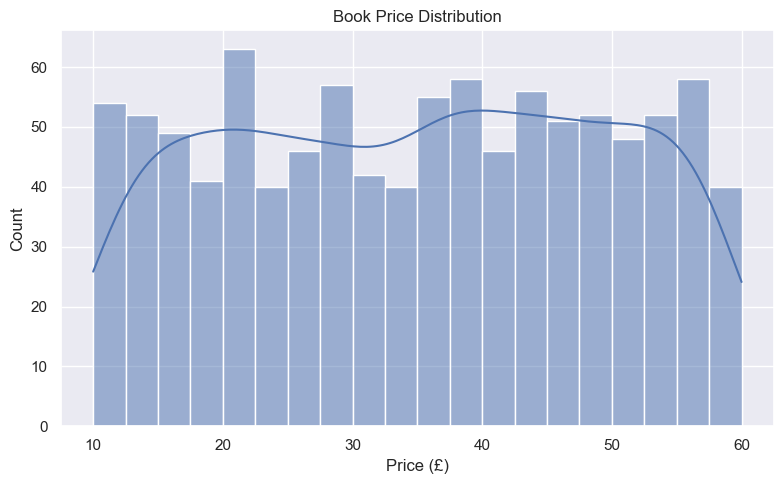

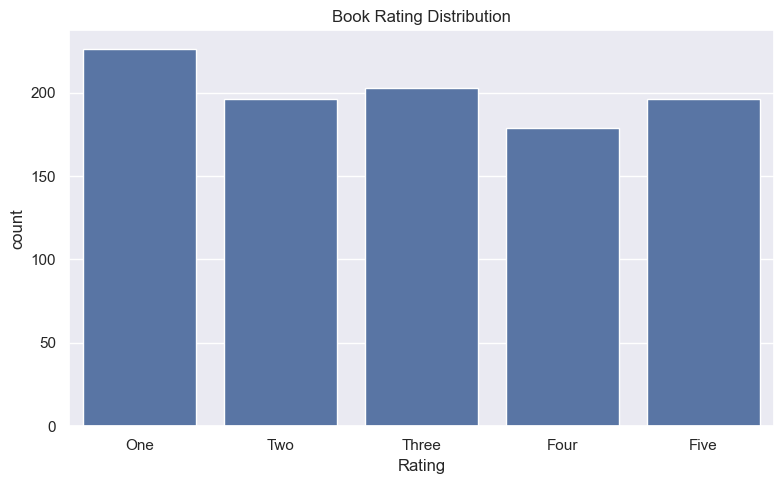

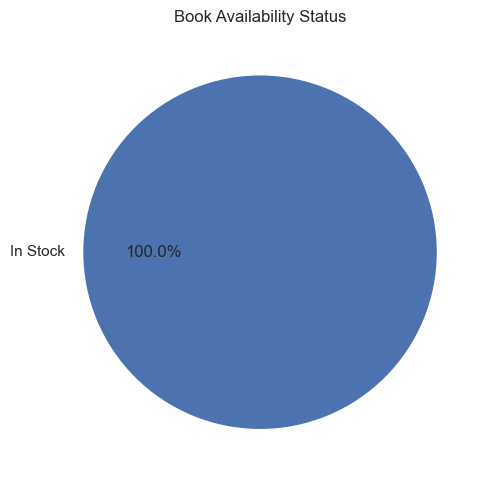

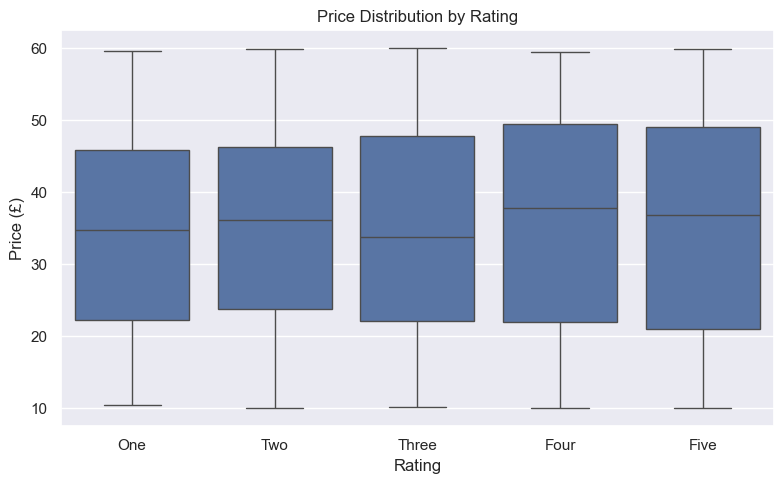

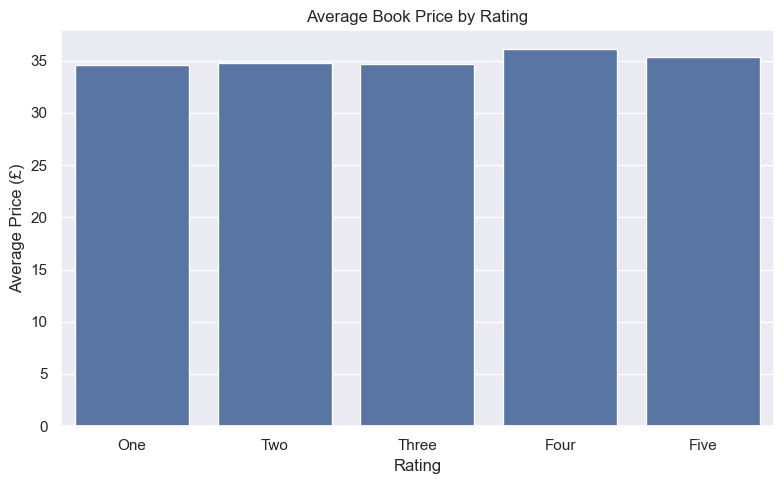

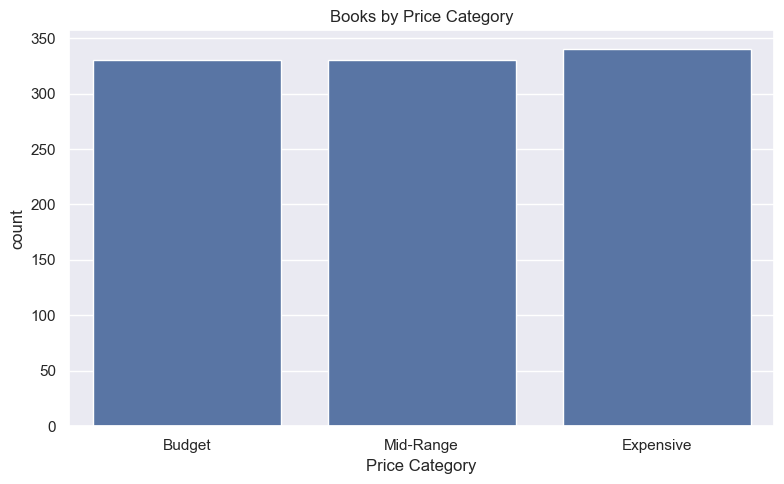

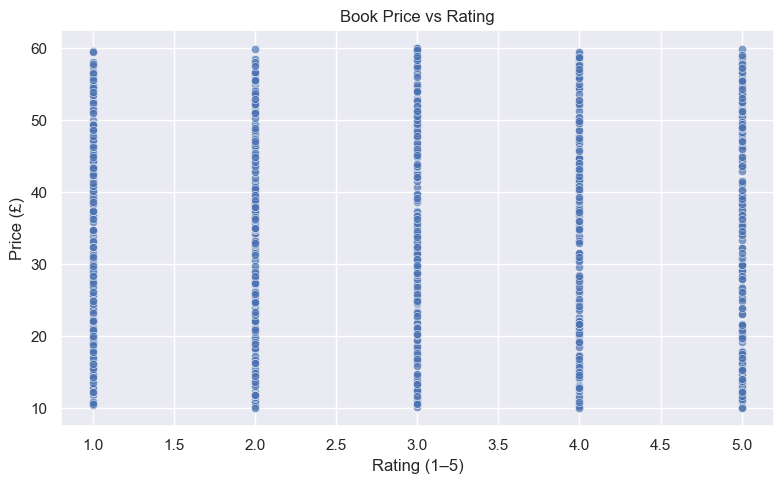

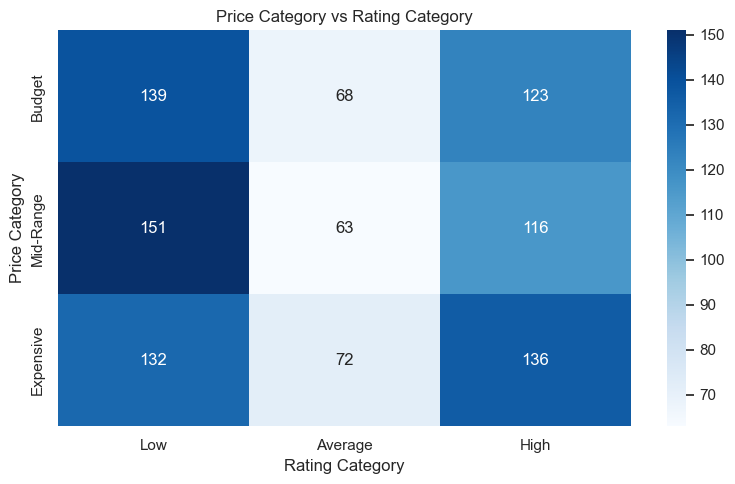

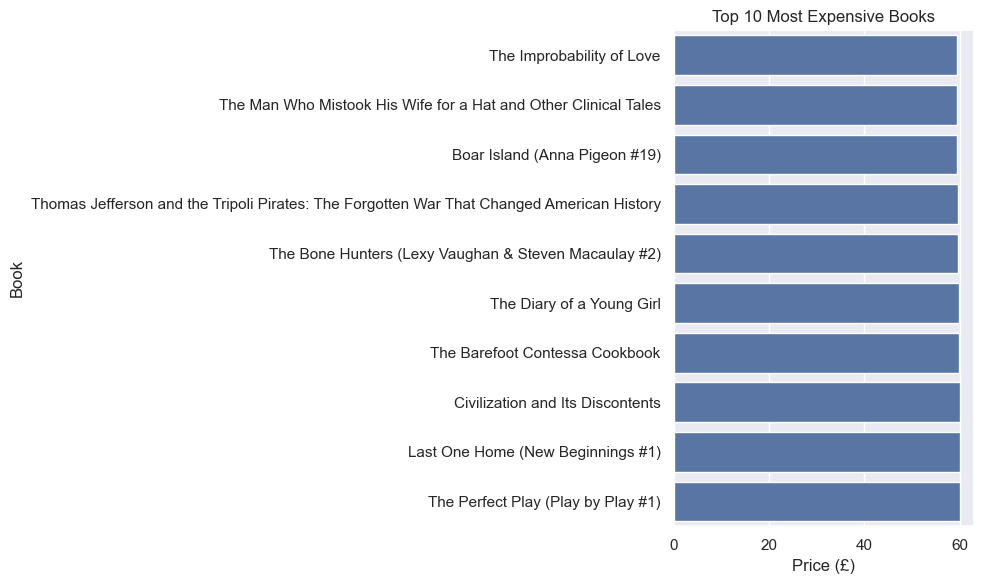

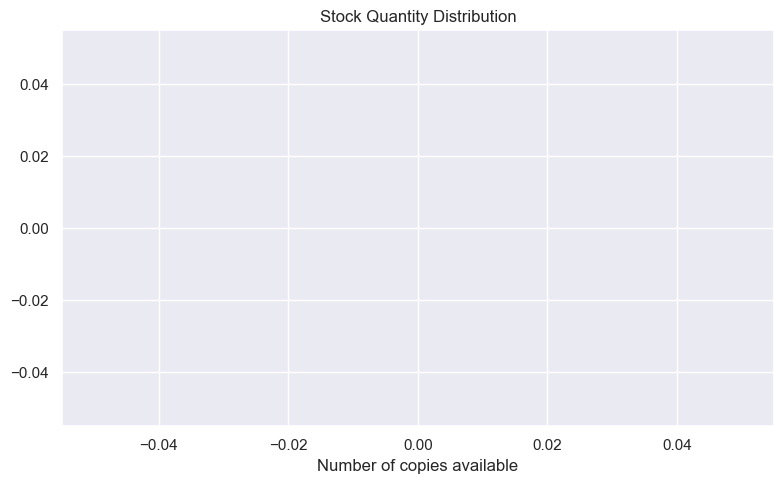

In [10]:
## 5. Exploratory Data Analysis (EDA)
### Univariate analysis
print("Dataset shape:", clean_df.shape)
display(clean_df[["Price", "Rating_Score", "Stock_Count"]].describe())
display(clean_df["Rating"].value_counts(dropna=False))
display(clean_df["Availability_Status"].value_counts(dropna=False))

### Create at least 8 visualizations
sns.set_theme()

def save_chart(filename):
    plt.tight_layout()
    plt.savefig(CHART_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

# 1. Price distribution – univariate
plt.figure(figsize=(8, 5))
sns.histplot(clean_df["Price"], bins=20, kde=True)
plt.title("Book Price Distribution")
plt.xlabel("Price (£)")
save_chart("01_price_distribution.png")

# 2. Rating count – univariate
plt.figure(figsize=(8, 5))
order = ["One", "Two", "Three", "Four", "Five"]
sns.countplot(data=clean_df, x="Rating", order=order)
plt.title("Book Rating Distribution")
plt.xlabel("Rating")
save_chart("02_rating_distribution.png")

# 3. Availability – univariate
plt.figure(figsize=(7, 5))
clean_df["Availability_Status"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Book Availability Status")
plt.ylabel("")
save_chart("03_availability_distribution.png")

# 4. Price by rating – bivariate
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_df, x="Rating", y="Price", order=order)
plt.title("Price Distribution by Rating")
plt.xlabel("Rating")
plt.ylabel("Price (£)")
save_chart("04_price_by_rating_boxplot.png")

# 5. Average price by rating – bivariate
plt.figure(figsize=(8, 5))
avg_price_rating = clean_df.groupby("Rating", observed=False)["Price"].mean().reindex(order)
sns.barplot(x=avg_price_rating.index, y=avg_price_rating.values)
plt.title("Average Book Price by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Price (£)")
save_chart("05_average_price_by_rating.png")

# 6. Price category distribution – univariate
plt.figure(figsize=(8, 5))
sns.countplot(data=clean_df, x="Price_Category",
              order=["Budget", "Mid-Range", "Expensive"])
plt.title("Books by Price Category")
plt.xlabel("Price Category")
save_chart("06_price_category_distribution.png")

# 7. Price vs rating – bivariate
plt.figure(figsize=(8, 5))
sns.scatterplot(data=clean_df, x="Rating_Score", y="Price", alpha=0.7)
plt.title("Book Price vs Rating")
plt.xlabel("Rating (1–5)")
plt.ylabel("Price (£)")
save_chart("07_price_vs_rating_scatter.png")

# 8. Price category and rating category – multivariate
plt.figure(figsize=(8, 5))
cross_tab = pd.crosstab(clean_df["Price_Category"], clean_df["Rating_Category"])
sns.heatmap(cross_tab, annot=True, fmt="d", cmap="Blues")
plt.title("Price Category vs Rating Category")
plt.xlabel("Rating Category")
plt.ylabel("Price Category")
save_chart("08_price_rating_heatmap.png")

# 9. Top 10 expensive books – bivariate
plt.figure(figsize=(10, 6))
top10 = clean_df.nlargest(10, "Price").sort_values("Price")
sns.barplot(data=top10, x="Price", y="Book_Name")
plt.title("Top 10 Most Expensive Books")
plt.xlabel("Price (£)")
plt.ylabel("Book")
save_chart("09_top_10_expensive_books.png")

# 10. Stock quantity distribution – univariate
plt.figure(figsize=(8, 5))
sns.histplot(clean_df["Stock_Count"].dropna(), bins=15)
plt.title("Stock Quantity Distribution")
plt.xlabel("Number of copies available")
save_chart("10_stock_quantity_distribution.png")


In [11]:
## 6. Business questions with answers
answers = {
    "Q1. How many books were collected?": f"{len(clean_df)} books.",
    "Q2. What is the average book price?": f"£{clean_df['Price'].mean():.2f}.",
    "Q3. What is the minimum book price?": f"£{clean_df['Price'].min():.2f}.",
    "Q4. What is the maximum book price?": f"£{clean_df['Price'].max():.2f}.",
    "Q5. What is the median book price?": f"£{clean_df['Price'].median():.2f}.",
    "Q6. What is the average book rating?": f"{clean_df['Rating_Score'].mean():.2f} out of 5.",
    "Q7. Which rating has the highest number of books?": (
        f"{clean_df['Rating'].value_counts().idxmax()} stars "
        f"({clean_df['Rating'].value_counts().max()} books)."
    ),
    "Q8. How many books received a 5-star rating?": (
        f"{int((clean_df['Rating_Score'] == 5).sum())} books."
    ),
    "Q9. What is the availability status of the collected books?": (
        clean_df["Availability_Status"].value_counts(dropna=False).to_dict()
    ),
    "Q10. How many books were collected per catalogue page on average?": (
        f"{len(clean_df) / max(clean_df['Catalogue_Page_URL'].nunique(), 1):.1f} books."
    )
}
for question, answer in answers.items():
    print(question)
    print("Answer:", answer, "\\n")


Q1. How many books were collected?
Answer: 1000 books. \n
Q2. What is the average book price?
Answer: £35.07. \n
Q3. What is the minimum book price?
Answer: £10.00. \n
Q4. What is the maximum book price?
Answer: £59.99. \n
Q5. What is the median book price?
Answer: £35.98. \n
Q6. What is the average book rating?
Answer: 2.92 out of 5. \n
Q7. Which rating has the highest number of books?
Answer: One stars (226 books). \n
Q8. How many books received a 5-star rating?
Answer: 196 books. \n
Q9. What is the availability status of the collected books?
Answer: {'In Stock': 1000} \n
Q10. How many books were collected per catalogue page on average?
Answer: 20.0 books. \n


In [12]:
## 7. Business insights – generated from the collected data
rating_counts = clean_df["Rating"].value_counts()
price_by_rating = clean_df.groupby("Rating", observed=False)["Price"].mean().dropna()
price_category_counts = clean_df["Price_Category"].value_counts()
availability_counts = clean_df["Availability_Status"].value_counts()

insights = [
    f"The dataset contains {len(clean_df)} unique book records after cleaning.",
    f"The average listed book price is £{clean_df['Price'].mean():.2f}, while the median is £{clean_df['Price'].median():.2f}.",
    f"The most common rating is {rating_counts.idxmax()} stars, representing {rating_counts.max()} books.",
    f"There are {int((clean_df['Rating_Score'] == 5).sum())} five-star books in the collected catalogue.",
    f"The highest-priced book is '{clean_df.loc[clean_df['Price'].idxmax(), 'Book_Name']}' at £{clean_df['Price'].max():.2f}.",
    f"The lowest-priced book is '{clean_df.loc[clean_df['Price'].idxmin(), 'Book_Name']}' at £{clean_df['Price'].min():.2f}.",
    f"The largest price segment is {price_category_counts.idxmax()} with {price_category_counts.max()} books.",
    f"Availability counts in the scrape are {availability_counts.to_dict()}."
]
for i, item in enumerate(insights, 1):
    print(f"{i}. {item}")

1. The dataset contains 1000 unique book records after cleaning.
2. The average listed book price is £35.07, while the median is £35.98.
3. The most common rating is One stars, representing 226 books.
4. There are 196 five-star books in the collected catalogue.
5. The highest-priced book is 'The Perfect Play (Play by Play #1)' at £59.99.
6. The lowest-priced book is 'An Abundance of Katherines' at £10.00.
7. The largest price segment is Expensive with 340 books.
8. Availability counts in the scrape are {'In Stock': 1000}.


In [13]:
## 8. Business recommendations
recommendations = [
    "Use the observed price distribution to create clear budget, mid-range and premium book collections.",
    "Highlight highly rated books in recommendation sections, while retaining enough variety across price points.",
    "Monitor books with low stock counts and prioritize replenishment where demand indicators are strong.",
    "Use rating and price together when planning promotions; avoid assuming that higher price automatically means higher rating.",
    "Repeat the scrape periodically and compare price, rating and availability changes over time before making inventory decisions."
]
for i, item in enumerate(recommendations, 1):
    print(f"{i}. {item}")

1. Use the observed price distribution to create clear budget, mid-range and premium book collections.
2. Highlight highly rated books in recommendation sections, while retaining enough variety across price points.
3. Monitor books with low stock counts and prioritize replenishment where demand indicators are strong.
4. Use rating and price together when planning promotions; avoid assuming that higher price automatically means higher rating.
5. Repeat the scrape periodically and compare price, rating and availability changes over time before making inventory decisions.


In [14]:
## 9. Export project deliverables
# Save business questions, insights and recommendations.
report_path = OUTPUT_DIR / "business_questions_insights_recommendations.txt"
with open(report_path, "w", encoding="utf-8") as f:
    f.write("BOOKS MARKET ANALYSIS – BUSINESS QUESTIONS AND ANSWERS\\n\\n")
    for q, a in answers.items():
        f.write(q + "\\n" + "Answer: " + str(a) + "\\n\\n")
    f.write("\\nBUSINESS INSIGHTS\\n")
    for i, item in enumerate(insights, 1):
        f.write(f"{i}. {item}\\n")
    f.write("\\nBUSINESS RECOMMENDATIONS\\n")
    for i, item in enumerate(recommendations, 1):
        f.write(f"{i}. {item}\\n")

# Save final CSVs in output folder.
scraped_df.to_csv(OUTPUT_DIR / "scraped_books.csv", index=False)
clean_df.to_csv(OUTPUT_DIR / "cleaned_books.csv", index=False)

print("Project outputs saved in:", OUTPUT_DIR.resolve())
print("Files:", [p.name for p in OUTPUT_DIR.iterdir()])


Project outputs saved in: C:\Users\peram\books_market_analysis_output
Files: ['business_questions_insights_recommendations.txt', 'cleaned_books.csv', 'scraped_books.csv', 'visualizations']


## 10. Conclusion

This project demonstrates an end-to-end analytics workflow using a public practice website. The scraped catalogue data is transformed into structured data, cleaned with Pandas and regular expressions, enriched with engineered features, and analyzed through visualizations and business questions.

**Important:** The figures in the notebook are calculated from the live scrape when the notebook is run. They may differ from figures in an earlier presentation if the website data changes or the earlier dataset was collected at a different time.
